In [78]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA
from statsforecast.arima import arima_string
import warnings
import scipy.stats as stats
warnings.filterwarnings('ignore')

In [14]:
df = pd.read_parquet("../data/clean_foreign_exchange_reserves.parquet")
df.tail()

,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,...,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay
7,2020,65.861667,24.295000,27.550833,352.696667,54.590833,88.800833,37.432500,3262.677500,55.978333,...,893.277500,416.920833,68.095000,523.429167,892.870000,7610.353333,90.010000,135.418333,208.609167,8.899167
8,2021,68.871667,26.110000,30.481667,359.058333,58.371667,94.895833,47.328333,3366.054167,58.872500,...,827.308333,456.841667,71.934167,509.424167,987.581667,7982.624167,105.070833,187.279167,218.990833,9.987500
9,2022,81.175833,31.935833,38.776667,341.515833,66.012500,105.453333,44.143333,3293.893333,57.351667,...,971.085833,438.766667,86.178333,621.454167,937.484167,7815.097500,109.914167,240.817500,212.458333,9.538333
10,2023,90.190000,29.365000,37.916667,342.240833,72.271667,113.250833,41.015000,3368.925000,58.023333,...,1141.587500,421.241667,90.910833,639.941667,781.061667,7629.345000,119.994167,244.194167,208.479167,9.898333
11,2024,94.169167,31.460833,38.988333,357.593333,75.389167,121.880000,45.374167,3482.501667,61.644167,...,1153.175833,415.433333,98.212500,662.369167,791.275000,8098.949167,143.194167,243.950000,217.076667,10.151667


In [15]:
df_aus = df[["Year", "Australia"]].copy()

In [16]:
df_aus

,Year,Australia
0,2013,52.751667
1,2014,60.172500
2,2015,62.596667
3,2016,60.568333
4,2017,73.416667
5,2018,71.986667
6,2019,73.037500
7,2020,65.861667
8,2021,68.871667
9,2022,81.175833


<Axes: xlabel='Year', ylabel='Australia'>

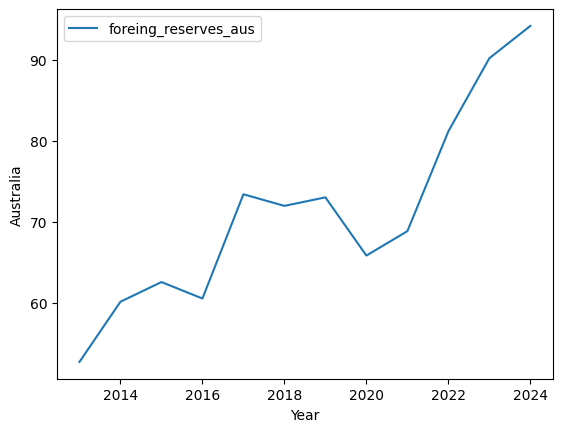

In [17]:
sns.lineplot(df_aus, x='Year', y='Australia', label='foreing_reserves_aus') 

In [18]:
df_aus['unique_id'] = '1'
df_aus.columns=['ds', 'y','unique_id']
df_aus.head()

,ds,y,unique_id
0,2013,52.751667,1
1,2014,60.172500,1
2,2015,62.596667,1
3,2016,60.568333,1
4,2017,73.416667,1


In [19]:
df_aus.dtypes

ds             Int64
y            float64
unique_id     object
dtype: object

In [20]:
df_aus['ds'] = pd.to_datetime(df_aus['ds'].astype(str) + '-01-01')
df_aus.head()

,ds,y,unique_id
0,2013-01-01,52.751667,1
1,2014-01-01,60.172500,1
2,2015-01-01,62.596667,1
3,2016-01-01,60.568333,1
4,2017-01-01,73.416667,1


In [22]:
Y_train_df_aus = df_aus[df_aus.ds<='2021-01-01']
Y_test_df_aus = df_aus[df_aus.ds>'2021-01-01']

In [23]:
Y_train_df_aus

,ds,y,unique_id
0,2013-01-01,52.751667,1
1,2014-01-01,60.172500,1
2,2015-01-01,62.596667,1
3,2016-01-01,60.568333,1
4,2017-01-01,73.416667,1
5,2018-01-01,71.986667,1
6,2019-01-01,73.037500,1
7,2020-01-01,65.861667,1
8,2021-01-01,68.871667,1


In [24]:
Y_test_df_aus

,ds,y,unique_id
9,2022-01-01,81.175833,1
10,2023-01-01,90.190000,1
11,2024-01-01,94.169167,1


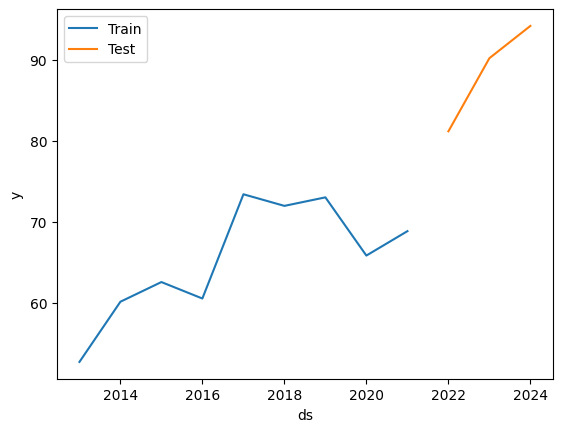

In [25]:
sns.lineplot(Y_train_df_aus, x='ds', y='y', label='Train')
sns.lineplot(Y_test_df_aus, x='ds', y='y', label='Test')
plt.show()

**Why the gap happens**

You're splitting the data at exactly '2021-01-01', so:
- Y_train_df_aus includes data up to and including '2021-01-01'
- Y_test_df_aus includes data after '2021-01-01'

**But here's the catch:** if your original df_aus doesn't have a data point exactly on '2021-01-01', then there's no shared boundary between the two datasets. That creates a visual gap in the plot.


In [26]:
# Instantiating Model

season_length = 1 # yearly data
horizon = len(Y_test_df_aus) # number of predictions

models = [AutoARIMA(season_length=season_length)]

In [53]:
# Initialize StatsForecast with AutoARIMA
sf_auto_arima = StatsForecast(
    models=models,
    freq='YS' # 'YS' for Yearly Start frequency
)

In [54]:
# Fit the model to your data
sf_auto_arima.fit(df=Y_train_df_aus)

StatsForecast(models=[AutoARIMA])

In [56]:
# see the parameters that the model has found
arima_string(sf_auto_arima.fitted_[0,0].model_)

'ARIMA(0,1,0)                   '

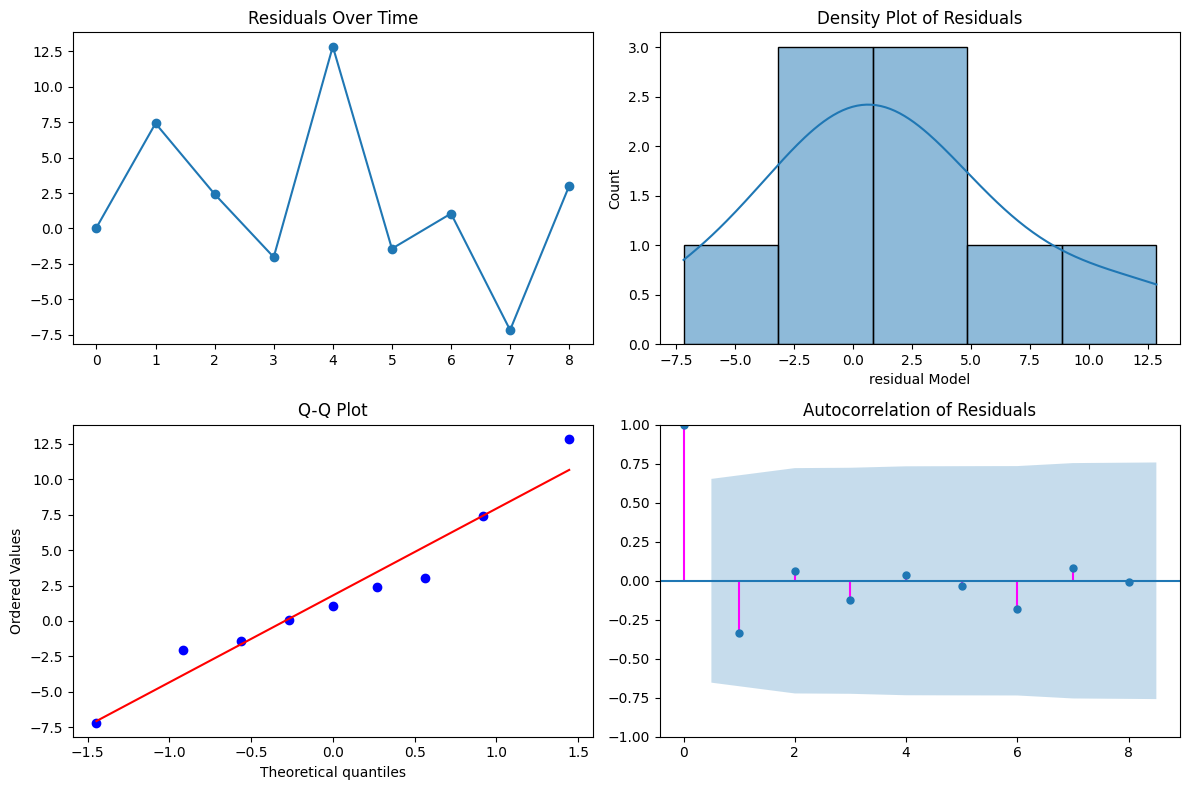

In [58]:
# Extract the residual series
residual_series = residual["residual Model"]

# Set up subplots
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))

# 1. Time series plot
axs[0, 0].plot(residual_series, marker='o', linestyle='-')
axs[0, 0].set_title("Residuals Over Time")

# 2. Histogram + KDE
sns.histplot(residual_series, kde=True, ax=axs[0, 1])
axs[0, 1].set_title("Density Plot of Residuals")

# 3. Q-Q plot
stats.probplot(residual_series, dist="norm", plot=axs[1, 0])
axs[1, 0].set_title("Q-Q Plot")

# 4. Autocorrelation plot
plot_acf(residual_series, lags=8, ax=axs[1, 1], vlines_kwargs={"color": "fuchsia"})
axs[1, 1].set_title("Autocorrelation of Residuals")

plt.tight_layout()
plt.show()


**1. Residuals Over Time**
- Purpose: Checks if residuals are randomly scattered.
- Good sign: No visible patterns, trends, or clustering. Just noise.
- Bad sign: Systematic drift or cycles—your model missed something.

**2. Density Plot (Histogram + KDE)**
- Purpose: Shows the distribution of residuals.
- Good sign: Bell-shaped curve centered around zero.
- Bad sign: Skewed or multimodal—suggests non-normal errors.

**3. Q-Q Plot**
- Purpose: Tests if residuals follow a normal distribution.
- Good sign: Points lie close to the diagonal line.
- Bad sign: Curved or scattered points—indicates non-normality.

**4. Autocorrelation Plot (ACF)**
- Purpose: Detects correlation between residuals at different lags.
- Good sign: All bars within confidence bounds—no autocorrelation.
- Bad sign: Significant spikes—model missed temporal structure
- The first bar is lag 0, which means you're comparing each value to itself.
- Since anything is perfectly similar to itself, the correlation is always 1.
- That’s why the first bar is always the tallest—it’s not a problem, just how math works.

In [59]:
# Forecast 3 steps ahead
forecast_df = sf.predict(h=horizon)
print(forecast_df)

  unique_id         ds    AutoETS
0         1 2022-01-01  68.547024
1         1 2023-01-01  68.547024
2         1 2024-01-01  68.547024


In [42]:
df_aus

,ds,y,unique_id
0,2013-01-01,52.751667,1
1,2014-01-01,60.172500,1
2,2015-01-01,62.596667,1
3,2016-01-01,60.568333,1
4,2017-01-01,73.416667,1
5,2018-01-01,71.986667,1
6,2019-01-01,73.037500,1
7,2020-01-01,65.861667,1
8,2021-01-01,68.871667,1
9,2022-01-01,81.175833,1


In [60]:
# other prove

models_2 = [AutoARIMA(season_length=season_length, seasonal=True)]
# Initialize StatsForecast with AutoARIMA
sf_auto_arima_2 = StatsForecast(
    models=models_2,
    freq='YS' # 'YS' for Yearly Start frequency
)

In [62]:
# Fit the model to your data
sf_auto_arima_2.fit(df=Y_train_df_aus)

# see the parameters that the model has found
arima_string(sf_auto_arima_2.fitted_[0,0].model_)

'ARIMA(0,1,0)                   '

In [63]:
from statsforecast.models import AutoETS

In [64]:
# Implementation of AutoETS with StatsForecast

sf_auto_ets = StatsForecast(models=[AutoETS(model="AZN")], freq='YS')

In [66]:
sf_auto_ets.fit(df=Y_train_df_aus)

StatsForecast(models=[AutoETS])

In [67]:
# Model Prediction
y_hat = sf_auto_ets.predict(h=horizon)
y_hat

,unique_id,ds,AutoETS
0,1,2022-01-01,68.547024
1,1,2023-01-01,68.547024
2,1,2024-01-01,68.547024


In [51]:
from statsforecast.models import ARIMA

In [68]:
sf_arima = StatsForecast(models=[ARIMA(order=(1, 1, 1))], freq='YS')

In [69]:
sf_arima.fit(Y_train_df_aus)

StatsForecast(models=[ARIMA])

In [70]:
y_forecast = sf_arima.predict(h=horizon)
y_forecast

,unique_id,ds,ARIMA
0,1,2022-01-01,69.004507
1,1,2023-01-01,69.048005
2,1,2024-01-01,69.062249


In [71]:
sf_arima_2 = StatsForecast(models=[ARIMA(order=(0, 1, 1))], freq='YS')

In [72]:
sf_arima_2.fit(Y_train_df_aus)

StatsForecast(models=[ARIMA])

In [73]:
y_forecast_2 = sf_arima_2.predict(h=horizon)
y_forecast_2

,unique_id,ds,ARIMA
0,1,2022-01-01,68.564923
1,1,2023-01-01,68.564923
2,1,2024-01-01,68.564923


In [74]:
sf_arima_3 = StatsForecast(models=[ARIMA(order=(0, 1, 2))], freq='YS')

In [75]:
sf_arima_3.fit(Y_train_df_aus)
y_forecast_3 = sf_arima_3.predict(h=horizon)
y_forecast_3

,unique_id,ds,ARIMA
0,1,2022-01-01,67.054881
1,1,2023-01-01,67.322026
2,1,2024-01-01,67.322026


In [76]:
sf_arima_4 = StatsForecast(models=[ARIMA(order=(1, 1, 2))], freq='YS')
sf_arima_4.fit(Y_train_df_aus)
y_forecast_4 = sf_arima_4.predict(h=horizon)
y_forecast_4

,unique_id,ds,ARIMA
0,1,2022-01-01,66.421631
1,1,2023-01-01,67.672541
2,1,2024-01-01,67.368417


# Otra idea completamente

- Volvemos a lo que no queriamos un regresor por cada macroeconomico y pais

In [79]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [80]:
class LimitedDataForecaster:
    """
    Comprehensive forecasting toolkit for time series with limited data points.
    Designed for macroeconomic data with yearly frequency.
    """
    
    def __init__(self, data, date_col='ds', value_col='y', unique_id_col='unique_id'):
        """
        Initialize the forecaster with your data structure.
        
        Parameters:
        -----------
        data : pd.DataFrame
            Your time series data
        date_col : str
            Name of the date column (default: 'ds')
        value_col : str
            Name of the value column (default: 'y')
        unique_id_col : str
            Name of the unique identifier column (default: 'unique_id')
        """
        self.data = data.copy()
        self.date_col = date_col
        self.value_col = value_col
        self.unique_id_col = unique_id_col
        
        # Ensure datetime format
        self.data[date_col] = pd.to_datetime(self.data[date_col])
        self.data = self.data.sort_values(date_col)
        
        # Create time index (years since start)
        self.data['time_index'] = (self.data[date_col].dt.year - 
                                  self.data[date_col].dt.year.min())
        
        self.models = {}
        self.forecasts = {}
        self.metrics = {}
        
    def prepare_features(self, add_polynomial=False, degree=2):
        """
        Prepare time-based features for regression models.
        
        Parameters:
        -----------
        add_polynomial : bool
            Whether to add polynomial features for capturing non-linear trends
        degree : int
            Degree of polynomial features (if add_polynomial=True)
        """
        X = self.data[['time_index']].copy()
        
        if add_polynomial and degree > 1:
            for d in range(2, degree + 1):
                X[f'time_index_{d}'] = X['time_index'] ** d
                
        return X
    
    def linear_regression_forecast(self, h=3, add_polynomial=False, degree=2):
        """
        Linear regression forecasting with time trend.
        
        Parameters:
        -----------
        h : int
            Forecast horizon (number of periods ahead)
        add_polynomial : bool
            Whether to include polynomial terms
        degree : int
            Degree of polynomial features
        """
        print("🔧 Fitting Linear Regression Model...")
        
        # Prepare features
        X = self.prepare_features(add_polynomial, degree)
        y = self.data[self.value_col].values
        
        # Fit model
        model = LinearRegression()
        model.fit(X, y)
        
        # Generate future time indices
        last_time_index = self.data['time_index'].max()
        future_indices = np.arange(last_time_index + 1, last_time_index + h + 1)
        
        # Prepare future features
        X_future = pd.DataFrame({'time_index': future_indices})
        if add_polynomial and degree > 1:
            for d in range(2, degree + 1):
                X_future[f'time_index_{d}'] = X_future['time_index'] ** d
        
        # Make predictions
        predictions = model.predict(X_future)
        
        # Calculate confidence intervals (approximate)
        residuals = y - model.predict(X)
        mse = np.mean(residuals**2)
        std_error = np.sqrt(mse)
        
        # Store results
        self.models['linear_regression'] = model
        self.forecasts['linear_regression'] = {
            'predictions': predictions,
            'lower_bound': predictions - 1.96 * std_error,
            'upper_bound': predictions + 1.96 * std_error,
            'residuals': residuals,
            'mse': mse,
            'model_summary': f"R² = {model.score(X, y):.4f}, Coefficients: {model.coef_}"
        }
        
        return predictions, std_error
    
    def lasso_regression_forecast(self, h=3, alpha=0.1, add_polynomial=False, degree=2):
        """
        LASSO regression with L1 regularization for feature selection.
        
        Parameters:
        -----------
        h : int
            Forecast horizon
        alpha : float
            Regularization strength (higher = more regularization)
        """
        print("🔧 Fitting LASSO Regression Model...")
        
        # Prepare features
        X = self.prepare_features(add_polynomial, degree)
        y = self.data[self.value_col].values
        
        # Standardize features for regularization
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)
        
        # Fit LASSO model
        model = Lasso(alpha=alpha, max_iter=2000)
        model.fit(X_scaled, y)
        
        # Generate future features
        last_time_index = self.data['time_index'].max()
        future_indices = np.arange(last_time_index + 1, last_time_index + h + 1)
        
        X_future = pd.DataFrame({'time_index': future_indices})
        if add_polynomial and degree > 1:
            for d in range(2, degree + 1):
                X_future[f'time_index_{d}'] = X_future['time_index'] ** d
        
        X_future_scaled = scaler.transform(X_future)
        
        # Make predictions
        predictions = model.predict(X_future_scaled)
        
        # Calculate metrics
        residuals = y - model.predict(X_scaled)
        mse = np.mean(residuals**2)
        std_error = np.sqrt(mse)
        
        # Store results
        self.models['lasso'] = {'model': model, 'scaler': scaler}
        self.forecasts['lasso'] = {
            'predictions': predictions,
            'lower_bound': predictions - 1.96 * std_error,
            'upper_bound': predictions + 1.96 * std_error,
            'residuals': residuals,
            'mse': mse,
            'alpha': alpha,
            'model_summary': f"Active features: {np.sum(model.coef_ != 0)}/{len(model.coef_)}"
        }
        
        return predictions, std_error
    
    def ridge_regression_forecast(self, h=3, alpha=1.0, add_polynomial=False, degree=2):
        """
        Ridge regression with L2 regularization.
        
        Parameters:
        -----------
        h : int
            Forecast horizon
        alpha : float
            Regularization strength
        """
        print("🔧 Fitting Ridge Regression Model...")
        
        # Prepare features
        X = self.prepare_features(add_polynomial, degree)
        y = self.data[self.value_col].values
        
        # Standardize features
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)
        
        # Fit Ridge model
        model = Ridge(alpha=alpha)
        model.fit(X_scaled, y)
        
        # Generate future features
        last_time_index = self.data['time_index'].max()
        future_indices = np.arange(last_time_index + 1, last_time_index + h + 1)
        
        X_future = pd.DataFrame({'time_index': future_indices})
        if add_polynomial and degree > 1:
            for d in range(2, degree + 1):
                X_future[f'time_index_{d}'] = X_future['time_index'] ** d
        
        X_future_scaled = scaler.transform(X_future)
        
        # Make predictions
        predictions = model.predict(X_future_scaled)
        
        # Calculate metrics
        residuals = y - model.predict(X_scaled)
        mse = np.mean(residuals**2)
        std_error = np.sqrt(mse)
        
        # Store results
        self.models['ridge'] = {'model': model, 'scaler': scaler}
        self.forecasts['ridge'] = {
            'predictions': predictions,
            'lower_bound': predictions - 1.96 * std_error,
            'upper_bound': predictions + 1.96 * std_error,
            'residuals': residuals,
            'mse': mse,
            'alpha': alpha,
            'model_summary': f"Ridge α={alpha}, R² = {model.score(X_scaled, y):.4f}"
        }
        
        return predictions, std_error
    
    def exponential_smoothing_trend_forecast(self, h=3, alpha=None, beta=None):
        """
        Holt's Exponential Smoothing (Double Exponential Smoothing) with trend.
        Implements the method manually for better control with limited data.
        
        Parameters:
        -----------
        h : int
            Forecast horizon
        alpha : float or None
            Smoothing parameter for level (if None, optimized)
        beta : float or None
            Smoothing parameter for trend (if None, optimized)
        """
        print("🔧 Fitting Exponential Smoothing with Trend (Holt's Method)...")
        
        y = self.data[self.value_col].values
        n = len(y)
        
        # Grid search for optimal parameters if not provided
        best_alpha, best_beta = alpha, beta
        best_mse = float('inf')
        
        if alpha is None or beta is None:
            alpha_range = np.arange(0.1, 1.0, 0.1)
            beta_range = np.arange(0.1, 1.0, 0.1)
            
            for a in alpha_range:
                for b in beta_range:
                    try:
                        _, _, mse = self._holt_smoothing(y, a, b)
                        if mse < best_mse:
                            best_mse = mse
                            best_alpha, best_beta = a, b
                    except:
                        continue
        
        # Fit final model with best parameters
        level, trend, mse = self._holt_smoothing(y, best_alpha, best_beta)
        
        # Generate forecasts
        predictions = np.array([level[-1] + trend[-1] * i for i in range(1, h + 1)])
        
        # Calculate prediction intervals
        residuals = y[1:] - (level[:-1] + trend[:-1])
        std_error = np.sqrt(np.mean(residuals**2))
        
        # Store results
        self.models['exponential_smoothing'] = {
            'alpha': best_alpha, 
            'beta': best_beta,
            'final_level': level[-1],
            'final_trend': trend[-1]
        }
        
        self.forecasts['exponential_smoothing'] = {
            'predictions': predictions,
            'lower_bound': predictions - 1.96 * std_error,
            'upper_bound': predictions + 1.96 * std_error,
            'residuals': residuals,
            'mse': mse,
            'model_summary': f"α={best_alpha:.3f}, β={best_beta:.3f}, Final Level={level[-1]:.2f}, Final Trend={trend[-1]:.2f}"
        }
        
        return predictions, std_error
    
    def _holt_smoothing(self, y, alpha, beta):
        """
        Internal method to implement Holt's exponential smoothing.
        """
        n = len(y)
        level = np.zeros(n)
        trend = np.zeros(n)
        
        # Initialize
        level[0] = y[0]
        trend[0] = y[1] - y[0] if n > 1 else 0
        
        # Recursive equations
        for t in range(1, n):
            level[t] = alpha * y[t] + (1 - alpha) * (level[t-1] + trend[t-1])
            trend[t] = beta * (level[t] - level[t-1]) + (1 - beta) * trend[t-1]
        
        # Calculate MSE for parameter optimization
        fitted = level[:-1] + trend[:-1]
        mse = np.mean((y[1:] - fitted)**2)
        
        return level, trend, mse
    
    def ensemble_forecast(self, h=3, weights=None):
        """
        Create ensemble forecast combining all methods.
        
        Parameters:
        -----------
        h : int
            Forecast horizon
        weights : dict or None
            Weights for each method (if None, equal weights)
        """
        print("🔧 Creating Ensemble Forecast...")
        
        # Run all methods
        self.linear_regression_forecast(h)
        self.lasso_regression_forecast(h, alpha=0.1)
        self.ridge_regression_forecast(h, alpha=1.0)
        self.exponential_smoothing_trend_forecast(h)
        
        # Default equal weights
        if weights is None:
            weights = {
                'linear_regression': 0.25,
                'lasso': 0.25,
                'ridge': 0.25,
                'exponential_smoothing': 0.25
            }
        
        # Combine forecasts
        ensemble_pred = np.zeros(h)
        for method, weight in weights.items():
            if method in self.forecasts:
                ensemble_pred += weight * self.forecasts[method]['predictions']
        
        # Calculate ensemble confidence intervals
        ensemble_std = np.sqrt(np.mean([
            np.var(self.forecasts[method]['predictions']) 
            for method in weights.keys() 
            if method in self.forecasts
        ]))
        
        self.forecasts['ensemble'] = {
            'predictions': ensemble_pred,
            'lower_bound': ensemble_pred - 1.96 * ensemble_std,
            'upper_bound': ensemble_pred + 1.96 * ensemble_std,
            'weights': weights,
            'model_summary': f"Ensemble of {len(weights)} methods"
        }
        
        return ensemble_pred, ensemble_std
    
    def cross_validate_alpha(self, method='lasso', alpha_range=None):
        """
        Cross-validation for regularization parameter using time series walk-forward.
        """
        if alpha_range is None:
            alpha_range = np.logspace(-3, 1, 20)  # 0.001 to 10
        
        y = self.data[self.value_col].values
        X = self.prepare_features()
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)
        
        cv_scores = []
        
        # Time series cross-validation (walk-forward)
        for alpha in alpha_range:
            scores = []
            for i in range(3, len(y)):  # Minimum 3 points for training
                X_train, y_train = X_scaled[:i], y[:i]
                X_test, y_test = X_scaled[i:i+1], y[i:i+1]
                
                if method == 'lasso':
                    model = Lasso(alpha=alpha, max_iter=2000)
                elif method == 'ridge':
                    model = Ridge(alpha=alpha)
                
                try:
                    model.fit(X_train, y_train)
                    pred = model.predict(X_test)
                    scores.append(mean_squared_error(y_test, pred))
                except:
                    scores.append(float('inf'))
            
            cv_scores.append(np.mean(scores))
        
        best_alpha = alpha_range[np.argmin(cv_scores)]
        print(f"📊 Best α for {method}: {best_alpha:.4f}")
        
        return best_alpha, alpha_range, cv_scores
    
    def evaluate_forecasts(self, actual_values=None):
        """
        Evaluate forecast performance if actual values are available.
        
        Parameters:
        -----------
        actual_values : array-like or None
            Actual values for the forecast period (for validation)
        """
        if actual_values is None:
            print("ℹ️  No actual values provided for evaluation.")
            return None
        
        actual_values = np.array(actual_values)
        evaluation = {}
        
        for method, forecast_data in self.forecasts.items():
            predictions = forecast_data['predictions']
            
            # Calculate metrics
            mae = mean_absolute_error(actual_values, predictions)
            mse = mean_squared_error(actual_values, predictions)
            rmse = np.sqrt(mse)
            mape = np.mean(np.abs((actual_values - predictions) / actual_values)) * 100
            
            evaluation[method] = {
                'MAE': mae,
                'MSE': mse,
                'RMSE': rmse,
                'MAPE': mape
            }
        
        self.metrics = evaluation
        return evaluation
    
    def plot_forecasts(self, actual_values=None, figsize=(15, 10)):
        """
        Plot all forecasts with historical data.
        """
        fig, axes = plt.subplots(2, 2, figsize=figsize)
        axes = axes.flatten()
        
        # Get date range for forecasts
        last_date = self.data[self.date_col].max()
        forecast_dates = pd.date_range(
            start=last_date + pd.DateOffset(years=1), 
            periods=len(list(self.forecasts.values())[0]['predictions']), 
            freq='YS'
        )
        
        methods = ['linear_regression', 'lasso', 'ridge', 'exponential_smoothing']
        titles = ['Linear Regression', 'LASSO Regression', 'Ridge Regression', 'Exponential Smoothing + Trend']
        
        for idx, (method, title) in enumerate(zip(methods, titles)):
            ax = axes[idx]
            
            # Plot historical data
            ax.plot(self.data[self.date_col], self.data[self.value_col], 
                   'o-', label='Historical Data', linewidth=2, markersize=6)
            
            if method in self.forecasts:
                forecast_data = self.forecasts[method]
                
                # Plot forecast
                ax.plot(forecast_dates, forecast_data['predictions'], 
                       's-', label='Forecast', linewidth=2, markersize=8, color='red')
                
                # Plot confidence intervals
                ax.fill_between(forecast_dates, 
                              forecast_data['lower_bound'], 
                              forecast_data['upper_bound'],
                              alpha=0.3, color='red', label='95% CI')
                
                # Plot actual values if available
                if actual_values is not None:
                    ax.plot(forecast_dates, actual_values, 
                           '^-', label='Actual', linewidth=2, markersize=8, color='green')
            
            ax.set_title(f'{title}', fontsize=12, fontweight='bold')
            ax.set_ylabel('Value')
            ax.legend()
            ax.grid(True, alpha=0.3)
            
        plt.tight_layout()
        plt.show()
    
    def generate_forecast_report(self):
        """
        Generate a comprehensive report of all forecasting methods.
        """
        print("📊 FORECASTING REPORT")
        print("=" * 50)
        print(f"Data Period: {self.data[self.date_col].min().strftime('%Y')} - {self.data[self.date_col].max().strftime('%Y')}")
        print(f"Training Points: {len(self.data)}")
        print(f"Forecast Horizon: {len(list(self.forecasts.values())[0]['predictions'])} years")
        print()
        
        for method, forecast_data in self.forecasts.items():
            print(f"🔹 {method.upper().replace('_', ' ')}")
            print(f"   Model: {forecast_data['model_summary']}")
            print(f"   Predictions: {[f'{p:.2f}' for p in forecast_data['predictions']]}")
            if 'mse' in forecast_data:
                print(f"   Training MSE: {forecast_data['mse']:.4f}")
            print()

In [81]:
df_aus

,ds,y,unique_id
0,2013-01-01,52.751667,1
1,2014-01-01,60.172500,1
2,2015-01-01,62.596667,1
3,2016-01-01,60.568333,1
4,2017-01-01,73.416667,1
5,2018-01-01,71.986667,1
6,2019-01-01,73.037500,1
7,2020-01-01,65.861667,1
8,2021-01-01,68.871667,1
9,2022-01-01,81.175833,1


In [82]:
# Initialize and run
forecaster = LimitedDataForecaster(df_aus)
forecaster.ensemble_forecast(h=horizon)

🔧 Creating Ensemble Forecast...
🔧 Fitting Linear Regression Model...
🔧 Fitting LASSO Regression Model...
🔧 Fitting Ridge Regression Model...
🔧 Fitting Exponential Smoothing with Trend (Holt's Method)...


(array([92.76862188, 96.28522772, 99.80183355]),
 np.float64(2.9730858840148344))

📊 FORECASTING REPORT
Data Period: 2013 - 2024
Training Points: 12
Forecast Horizon: 3 years

🔹 LINEAR REGRESSION
   Model: R² = 0.7982, Coefficients: [3.06191142]
   Predictions: ['91.14', '94.20', '97.26']
   Training MSE: 28.2386

🔹 LASSO
   Model: Active features: 1/1
   Predictions: ['90.95', '93.98', '97.01']
   Training MSE: 28.2486

🔹 RIDGE
   Model: Ridge α=1.0, R² = 0.7935
   Predictions: ['89.60', '92.43', '95.26']
   Training MSE: 28.8997

🔹 EXPONENTIAL SMOOTHING
   Model: α=0.900, β=0.100, Final Level=94.24, Final Trend=5.15
   Predictions: ['99.39', '104.53', '109.68']
   Training MSE: 46.1667

🔹 ENSEMBLE
   Model: Ensemble of 4 methods
   Predictions: ['92.77', '96.29', '99.80']



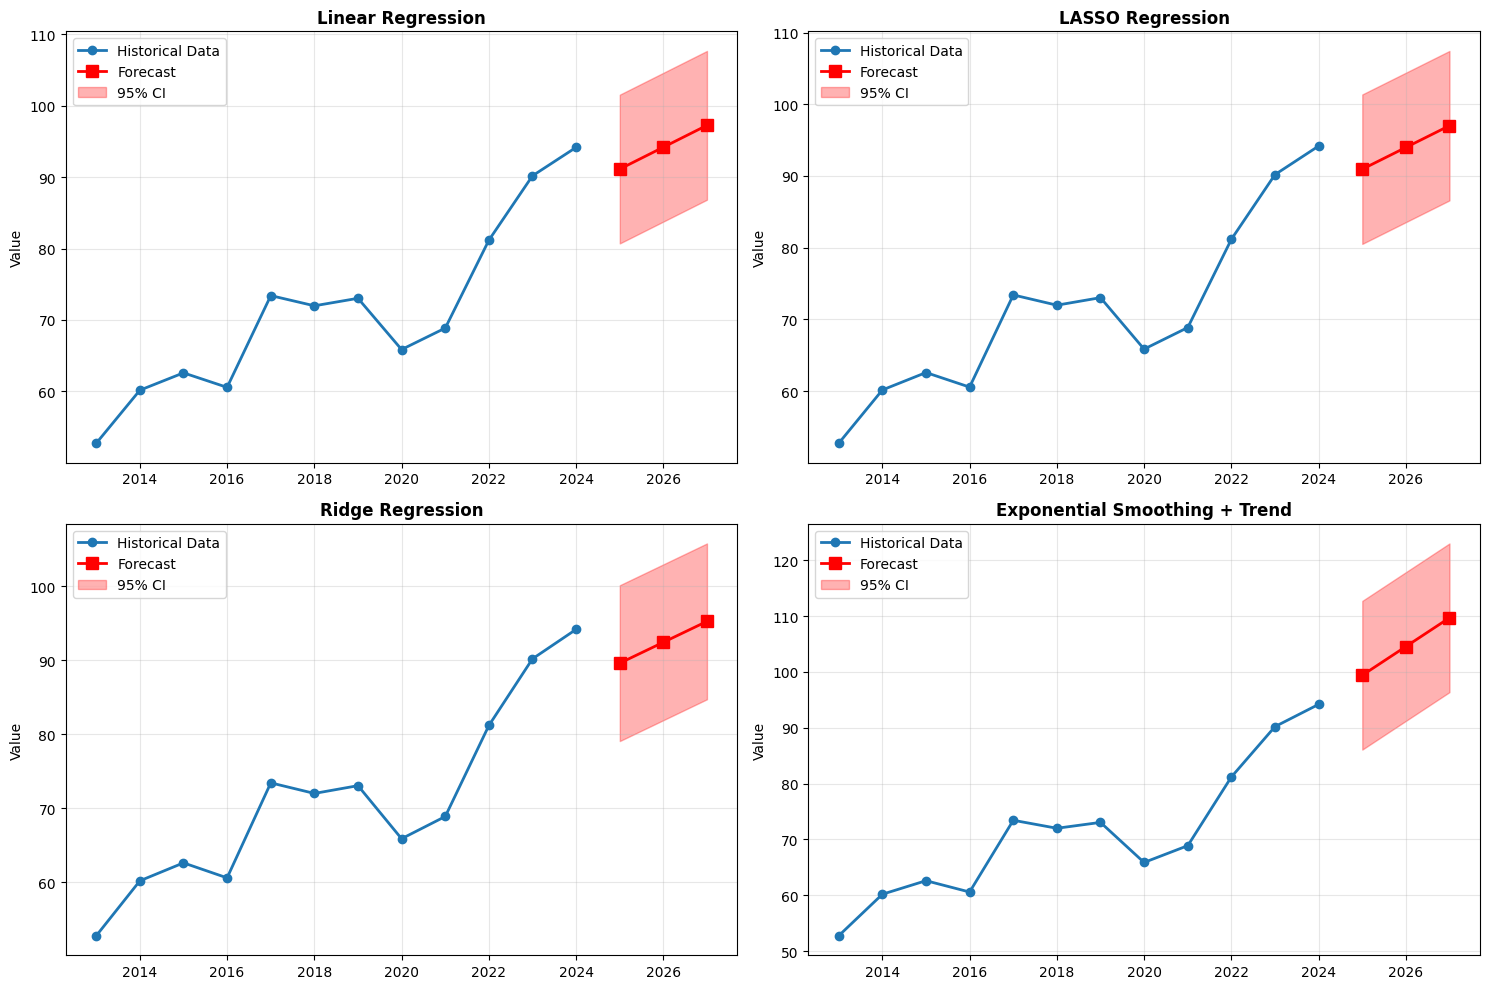

In [83]:
forecaster.generate_forecast_report()
forecaster.plot_forecasts()

In [84]:
forecaster = LimitedDataForecaster(Y_train_df_aus)
forecaster.ensemble_forecast(h=horizon)

🔧 Creating Ensemble Forecast...
🔧 Fitting Linear Regression Model...
🔧 Fitting LASSO Regression Model...
🔧 Fitting Ridge Regression Model...
🔧 Fitting Exponential Smoothing with Trend (Holt's Method)...


(array([72.68715212, 73.40797886, 74.12880561]),
 np.float64(1.6648803098647225))

📊 FORECASTING REPORT
Data Period: 2013 - 2021
Training Points: 9
Forecast Horizon: 3 years

🔹 LINEAR REGRESSION
   Model: R² = 0.5445, Coefficients: [1.89745833]
   Predictions: ['74.96', '76.86', '78.76']
   Training MSE: 20.0766

🔹 LASSO
   Model: Active features: 1/1
   Predictions: ['74.77', '76.63', '78.48']
   Training MSE: 20.0866

🔹 RIDGE
   Model: Ridge α=1.0, R² = 0.5391
   Predictions: ['74.01', '75.72', '77.43']
   Training MSE: 20.3166

🔹 EXPONENTIAL SMOOTHING
   Model: α=0.400, β=0.900, Final Level=69.59, Final Trend=-2.58
   Predictions: ['67.01', '64.43', '61.85']
   Training MSE: 35.8418

🔹 ENSEMBLE
   Model: Ensemble of 4 methods
   Predictions: ['72.69', '73.41', '74.13']



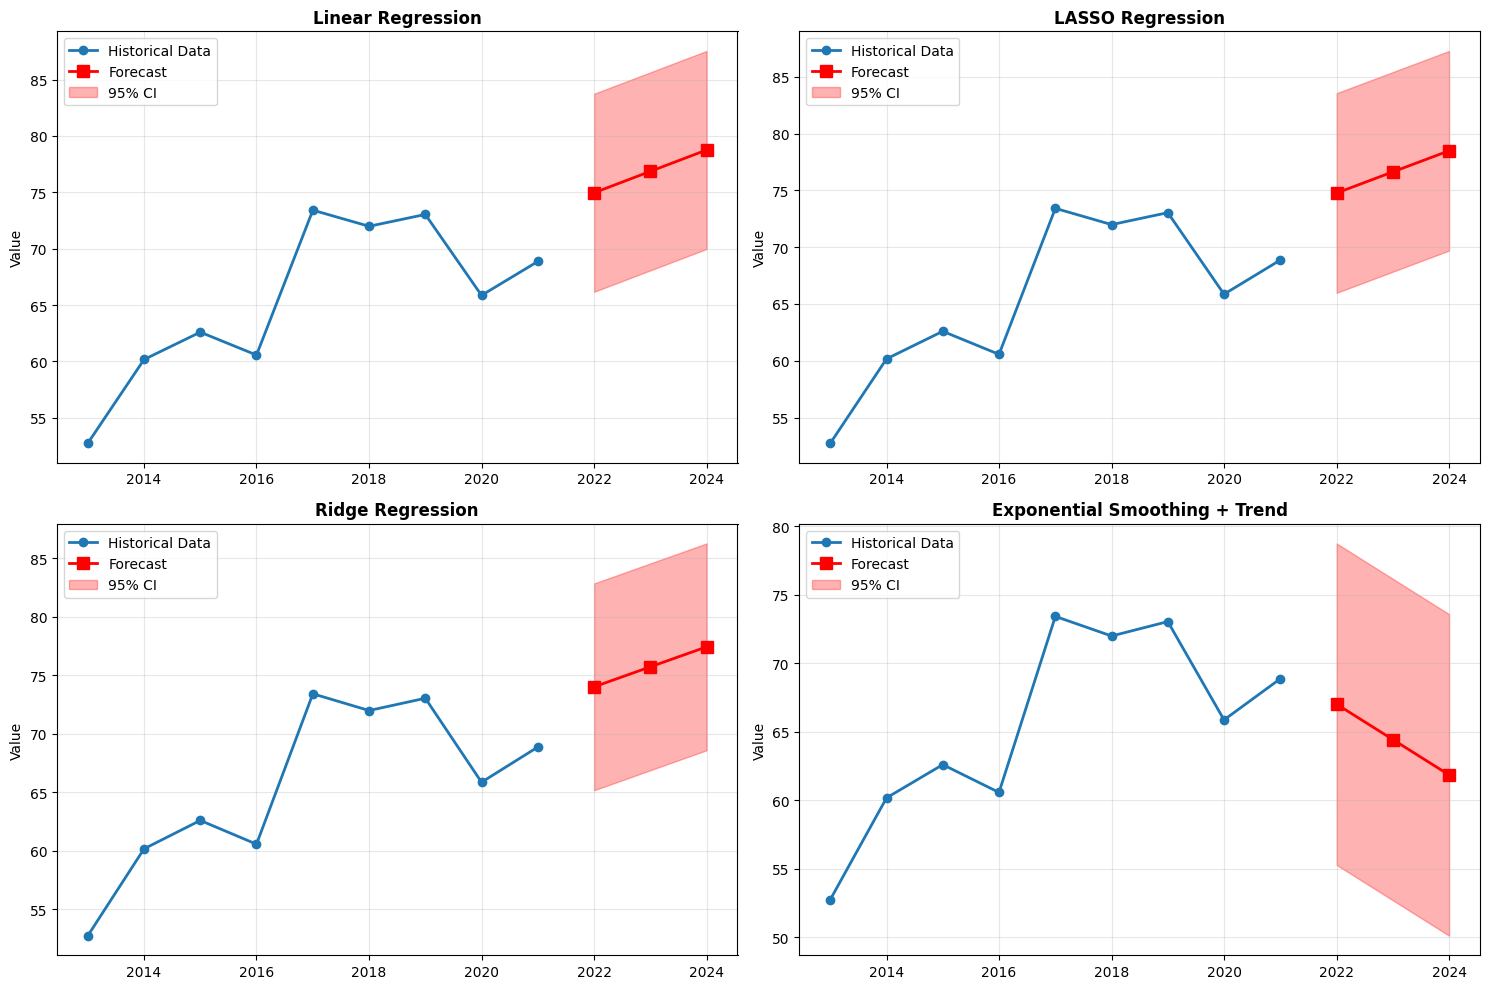

In [85]:
forecaster.generate_forecast_report()
forecaster.plot_forecasts()

In [86]:
Y_train_df_aus = df_aus[df_aus.ds<='2020-01-01']
Y_test_df_aus = df_aus[df_aus.ds>'2020-01-01']

In [88]:
forecaster = LimitedDataForecaster(Y_train_df_aus)
forecaster.ensemble_forecast(h=4)

🔧 Creating Ensemble Forecast...
🔧 Fitting Linear Regression Model...
🔧 Fitting LASSO Regression Model...
🔧 Fitting Ridge Regression Model...
🔧 Fitting Exponential Smoothing with Trend (Holt's Method)...


(array([73.88066445, 75.02690192, 76.17313939, 77.31937686]),
 np.float64(2.4865382351555394))

📊 FORECASTING REPORT
Data Period: 2013 - 2020
Training Points: 8
Forecast Horizon: 4 years

🔹 LINEAR REGRESSION
   Model: R² = 0.6027, Coefficients: [2.3465873]
   Predictions: ['75.61', '77.96', '80.30', '82.65']
   Training MSE: 19.0561

🔹 LASSO
   Model: Active features: 1/1
   Predictions: ['75.41', '77.72', '80.02', '82.32']
   Training MSE: 19.0661

🔹 RIDGE
   Model: Ridge α=1.0, R² = 0.5953
   Predictions: ['74.44', '76.52', '78.61', '80.69']
   Training MSE: 19.4130

🔹 EXPONENTIAL SMOOTHING
   Model: α=0.400, β=0.900, Final Level=72.22, Final Trend=-2.15
   Predictions: ['70.07', '67.92', '65.77', '63.62']
   Training MSE: 40.7581

🔹 ENSEMBLE
   Model: Ensemble of 4 methods
   Predictions: ['73.88', '75.03', '76.17', '77.32']



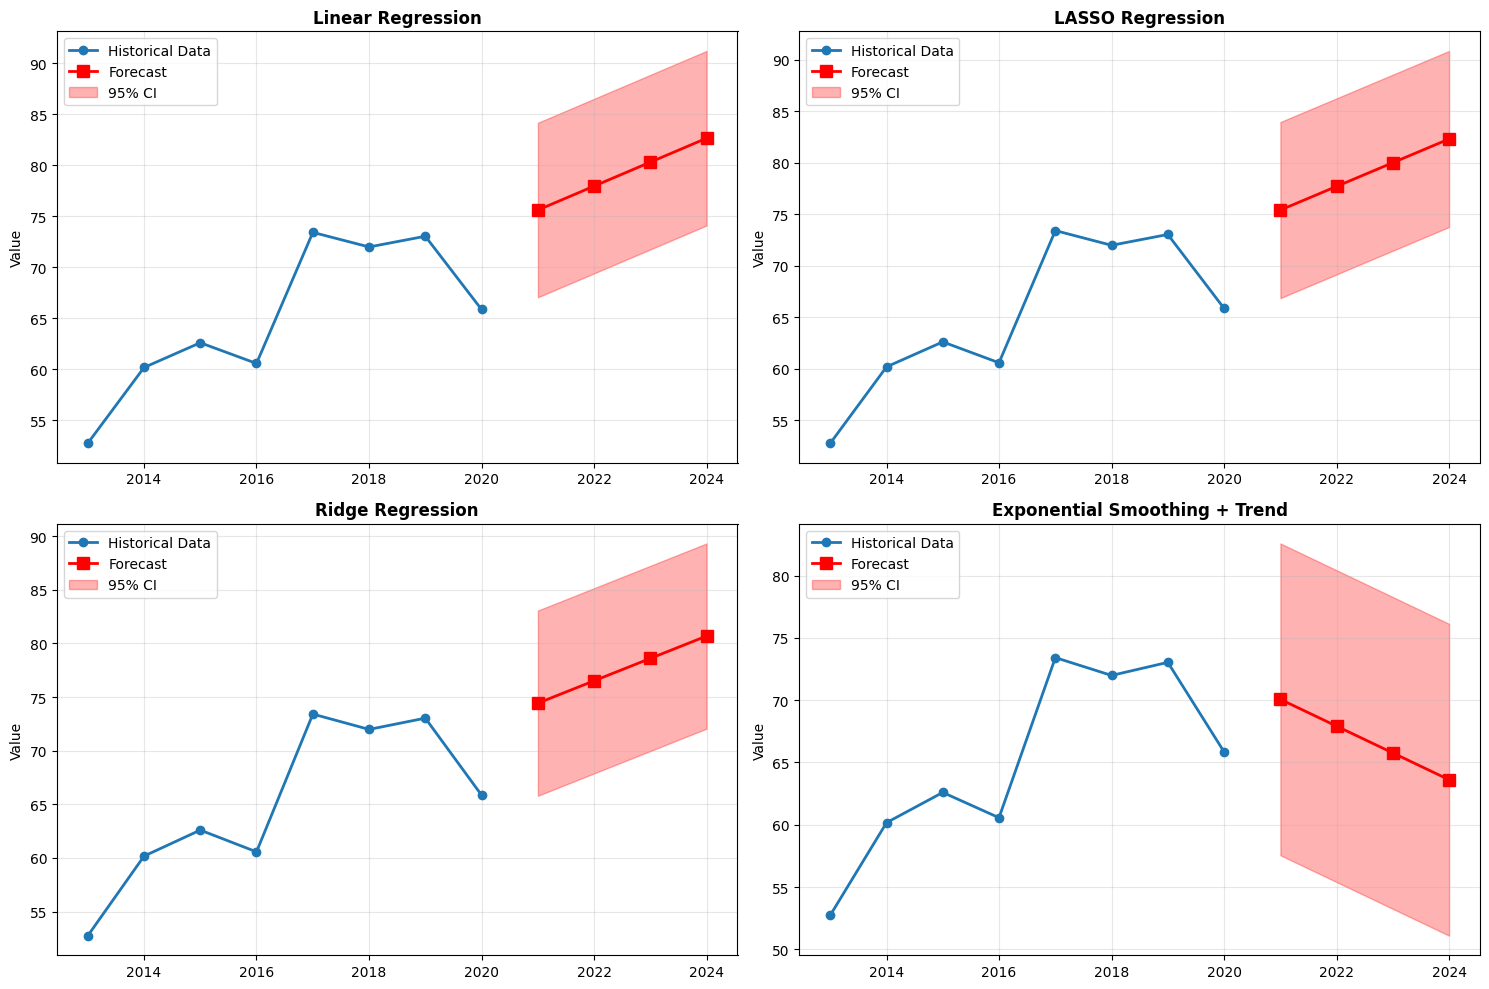

In [89]:
forecaster.generate_forecast_report()
forecaster.plot_forecasts()

In [90]:
class LimitedDataForecaster2:
    """
    Comprehensive forecasting toolkit for time series with limited data points.
    Designed for macroeconomic data with yearly frequency.
    """
    
    def __init__(self, data, date_col='ds', value_col='y', unique_id_col='unique_id'):
        """
        Initialize the forecaster with your data structure.
        
        Parameters:
        -----------
        data : pd.DataFrame
            Your time series data
        date_col : str
            Name of the date column (default: 'ds')
        value_col : str
            Name of the value column (default: 'y')
        unique_id_col : str
            Name of the unique identifier column (default: 'unique_id')
        """
        self.data = data.copy()
        self.date_col = date_col
        self.value_col = value_col
        self.unique_id_col = unique_id_col
        
        # Ensure datetime format
        self.data[date_col] = pd.to_datetime(self.data[date_col])
        self.data = self.data.sort_values(date_col)
        
        # Create time index (years since start)
        self.data['time_index'] = (self.data[date_col].dt.year - 
                                  self.data[date_col].dt.year.min())
        
        self.models = {}
        self.forecasts = {}
        self.metrics = {}
        
    def prepare_features(self, add_polynomial=False, degree=2):
        """
        Prepare time-based features for regression models.
        
        Parameters:
        -----------
        add_polynomial : bool
            Whether to add polynomial features for capturing non-linear trends
        degree : int
            Degree of polynomial features (if add_polynomial=True)
        """
        X = self.data[['time_index']].copy()
        
        if add_polynomial and degree > 1:
            for d in range(2, degree + 1):
                X[f'time_index_{d}'] = X['time_index'] ** d
                
        return X
    
    def linear_regression_forecast(self, h=3, add_polynomial=False, degree=2):
        """
        Linear regression forecasting with time trend.
        
        Parameters:
        -----------
        h : int
            Forecast horizon (number of periods ahead)
        add_polynomial : bool
            Whether to include polynomial terms
        degree : int
            Degree of polynomial features
        """
        print("🔧 Fitting Linear Regression Model...")
        
        # Prepare features
        X = self.prepare_features(add_polynomial, degree)
        y = self.data[self.value_col].values
        
        # Fit model
        model = LinearRegression()
        model.fit(X, y)
        
        # Generate future time indices
        last_time_index = self.data['time_index'].max()
        future_indices = np.arange(last_time_index + 1, last_time_index + h + 1)
        
        # Prepare future features
        X_future = pd.DataFrame({'time_index': future_indices})
        if add_polynomial and degree > 1:
            for d in range(2, degree + 1):
                X_future[f'time_index_{d}'] = X_future['time_index'] ** d
        
        # Make predictions
        predictions = model.predict(X_future)
        
        # Calculate confidence intervals (approximate)
        residuals = y - model.predict(X)
        mse = np.mean(residuals**2)
        std_error = np.sqrt(mse)
        
        # Store results
        self.models['linear_regression'] = model
        self.forecasts['linear_regression'] = {
            'predictions': predictions,
            'lower_bound': predictions - 1.96 * std_error,
            'upper_bound': predictions + 1.96 * std_error,
            'residuals': residuals,
            'mse': mse,
            'model_summary': f"R² = {model.score(X, y):.4f}, Coefficients: {model.coef_}"
        }
        
        return predictions, std_error
    
    def lasso_regression_forecast(self, h=3, alpha=0.1, add_polynomial=False, degree=2):
        """
        LASSO regression with L1 regularization for feature selection.
        
        Parameters:
        -----------
        h : int
            Forecast horizon
        alpha : float
            Regularization strength (higher = more regularization)
        """
        print("🔧 Fitting LASSO Regression Model...")
        
        # Prepare features
        X = self.prepare_features(add_polynomial, degree)
        y = self.data[self.value_col].values
        
        # Standardize features for regularization
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)
        
        # Fit LASSO model
        model = Lasso(alpha=alpha, max_iter=2000)
        model.fit(X_scaled, y)
        
        # Generate future features
        last_time_index = self.data['time_index'].max()
        future_indices = np.arange(last_time_index + 1, last_time_index + h + 1)
        
        X_future = pd.DataFrame({'time_index': future_indices})
        if add_polynomial and degree > 1:
            for d in range(2, degree + 1):
                X_future[f'time_index_{d}'] = X_future['time_index'] ** d
        
        X_future_scaled = scaler.transform(X_future)
        
        # Make predictions
        predictions = model.predict(X_future_scaled)
        
        # Calculate metrics
        residuals = y - model.predict(X_scaled)
        mse = np.mean(residuals**2)
        std_error = np.sqrt(mse)
        
        # Store results
        self.models['lasso'] = {'model': model, 'scaler': scaler}
        self.forecasts['lasso'] = {
            'predictions': predictions,
            'lower_bound': predictions - 1.96 * std_error,
            'upper_bound': predictions + 1.96 * std_error,
            'residuals': residuals,
            'mse': mse,
            'alpha': alpha,
            'model_summary': f"Active features: {np.sum(model.coef_ != 0)}/{len(model.coef_)}"
        }
        
        return predictions, std_error
    
    def ridge_regression_forecast(self, h=3, alpha=1.0, add_polynomial=False, degree=2):
        """
        Ridge regression with L2 regularization.
        
        Parameters:
        -----------
        h : int
            Forecast horizon
        alpha : float
            Regularization strength
        """
        print("🔧 Fitting Ridge Regression Model...")
        
        # Prepare features
        X = self.prepare_features(add_polynomial, degree)
        y = self.data[self.value_col].values
        
        # Standardize features
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)
        
        # Fit Ridge model
        model = Ridge(alpha=alpha)
        model.fit(X_scaled, y)
        
        # Generate future features
        last_time_index = self.data['time_index'].max()
        future_indices = np.arange(last_time_index + 1, last_time_index + h + 1)
        
        X_future = pd.DataFrame({'time_index': future_indices})
        if add_polynomial and degree > 1:
            for d in range(2, degree + 1):
                X_future[f'time_index_{d}'] = X_future['time_index'] ** d
        
        X_future_scaled = scaler.transform(X_future)
        
        # Make predictions
        predictions = model.predict(X_future_scaled)
        
        # Calculate metrics
        residuals = y - model.predict(X_scaled)
        mse = np.mean(residuals**2)
        std_error = np.sqrt(mse)
        
        # Store results
        self.models['ridge'] = {'model': model, 'scaler': scaler}
        self.forecasts['ridge'] = {
            'predictions': predictions,
            'lower_bound': predictions - 1.96 * std_error,
            'upper_bound': predictions + 1.96 * std_error,
            'residuals': residuals,
            'mse': mse,
            'alpha': alpha,
            'model_summary': f"Ridge α={alpha}, R² = {model.score(X_scaled, y):.4f}"
        }
        
        return predictions, std_error
    

    
    def ensemble_forecast(self, h=3, weights=None):
        """
        Create ensemble forecast combining all methods.
        
        Parameters:
        -----------
        h : int
            Forecast horizon
        weights : dict or None
            Weights for each method (if None, equal weights)
        """
        print("🔧 Creating Ensemble Forecast...")
        
        # Run all methods
        self.linear_regression_forecast(h)
        self.lasso_regression_forecast(h, alpha=0.1)
        self.ridge_regression_forecast(h, alpha=1.0)
        
        # Default equal weights for 3 methods
        if weights is None:
            weights = {
                'linear_regression': 1/3,
                'lasso': 1/3,
                'ridge': 1/3
            }
        
        # Combine forecasts
        ensemble_pred = np.zeros(h)
        for method, weight in weights.items():
            if method in self.forecasts:
                ensemble_pred += weight * self.forecasts[method]['predictions']
        
        # Calculate ensemble confidence intervals
        ensemble_std = np.sqrt(np.mean([
            np.var(self.forecasts[method]['predictions']) 
            for method in weights.keys() 
            if method in self.forecasts
        ]))
        
        self.forecasts['ensemble'] = {
            'predictions': ensemble_pred,
            'lower_bound': ensemble_pred - 1.96 * ensemble_std,
            'upper_bound': ensemble_pred + 1.96 * ensemble_std,
            'weights': weights,
            'model_summary': f"Ensemble of {len(weights)} methods"
        }
        
        return ensemble_pred, ensemble_std
    
    def cross_validate_alpha(self, method='lasso', alpha_range=None):
        """
        Cross-validation for regularization parameter using time series walk-forward.
        """
        if alpha_range is None:
            alpha_range = np.logspace(-3, 1, 20)  # 0.001 to 10
        
        y = self.data[self.value_col].values
        X = self.prepare_features()
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)
        
        cv_scores = []
        
        # Time series cross-validation (walk-forward)
        for alpha in alpha_range:
            scores = []
            for i in range(3, len(y)):  # Minimum 3 points for training
                X_train, y_train = X_scaled[:i], y[:i]
                X_test, y_test = X_scaled[i:i+1], y[i:i+1]
                
                if method == 'lasso':
                    model = Lasso(alpha=alpha, max_iter=2000)
                elif method == 'ridge':
                    model = Ridge(alpha=alpha)
                
                try:
                    model.fit(X_train, y_train)
                    pred = model.predict(X_test)
                    scores.append(mean_squared_error(y_test, pred))
                except:
                    scores.append(float('inf'))
            
            cv_scores.append(np.mean(scores))
        
        best_alpha = alpha_range[np.argmin(cv_scores)]
        print(f"📊 Best α for {method}: {best_alpha:.4f}")
        
        return best_alpha, alpha_range, cv_scores
    
    def evaluate_forecasts(self, actual_values=None):
        """
        Evaluate forecast performance if actual values are available.
        
        Parameters:
        -----------
        actual_values : array-like or None
            Actual values for the forecast period (for validation)
        """
        if actual_values is None:
            print("ℹ️  No actual values provided for evaluation.")
            return None
        
        actual_values = np.array(actual_values)
        evaluation = {}
        
        for method, forecast_data in self.forecasts.items():
            predictions = forecast_data['predictions']
            
            # Calculate metrics
            mae = mean_absolute_error(actual_values, predictions)
            mse = mean_squared_error(actual_values, predictions)
            rmse = np.sqrt(mse)
            mape = np.mean(np.abs((actual_values - predictions) / actual_values)) * 100
            
            evaluation[method] = {
                'MAE': mae,
                'MSE': mse,
                'RMSE': rmse,
                'MAPE': mape
            }
        
        self.metrics = evaluation
        return evaluation
    
    def plot_forecasts(self, actual_values=None, figsize=(15, 8)):
        """
        Plot all forecasts with historical data.
        """
        fig, axes = plt.subplots(1, 3, figsize=figsize)
        
        # Get date range for forecasts
        last_date = self.data[self.date_col].max()
        forecast_dates = pd.date_range(
            start=last_date + pd.DateOffset(years=1), 
            periods=len(list(self.forecasts.values())[0]['predictions']), 
            freq='YS'
        )
        
        methods = ['linear_regression', 'lasso', 'ridge']
        titles = ['Linear Regression', 'LASSO Regression', 'Ridge Regression']
        
        for idx, (method, title) in enumerate(zip(methods, titles)):
            ax = axes[idx]
            
            # Plot historical data
            ax.plot(self.data[self.date_col], self.data[self.value_col], 
                   'o-', label='Historical Data', linewidth=2, markersize=6)
            
            if method in self.forecasts:
                forecast_data = self.forecasts[method]
                
                # Plot forecast
                ax.plot(forecast_dates, forecast_data['predictions'], 
                       's-', label='Forecast', linewidth=2, markersize=8, color='red')
                
                # Plot confidence intervals
                ax.fill_between(forecast_dates, 
                              forecast_data['lower_bound'], 
                              forecast_data['upper_bound'],
                              alpha=0.3, color='red', label='95% CI')
                
                # Plot actual values if available
                if actual_values is not None:
                    ax.plot(forecast_dates, actual_values, 
                           '^-', label='Actual', linewidth=2, markersize=8, color='green')
            
            ax.set_title(f'{title}', fontsize=12, fontweight='bold')
            ax.set_ylabel('Value')
            ax.legend()
            ax.grid(True, alpha=0.3)
            
        plt.tight_layout()
        plt.show()
    
    def generate_forecast_report(self):
        """
        Generate a comprehensive report of all forecasting methods.
        """
        print("📊 FORECASTING REPORT")
        print("=" * 50)
        print(f"Data Period: {self.data[self.date_col].min().strftime('%Y')} - {self.data[self.date_col].max().strftime('%Y')}")
        print(f"Training Points: {len(self.data)}")
        print(f"Forecast Horizon: {len(list(self.forecasts.values())[0]['predictions'])} years")
        print()
        
        for method, forecast_data in self.forecasts.items():
            print(f"🔹 {method.upper().replace('_', ' ')}")
            print(f"   Model: {forecast_data['model_summary']}")
            print(f"   Predictions: {[f'{p:.2f}' for p in forecast_data['predictions']]}")
            if 'mse' in forecast_data:
                print(f"   Training MSE: {forecast_data['mse']:.4f}")
            print()

# Example usage and demonstration
def demo_forecasting():
    """
    Demonstration function showing how to use the forecaster.
    Replace this with your actual data.
    """
    # Create sample data similar to your structure
    # Replace this with your actual data loading
    np.random.seed(42)
    dates = pd.date_range('2013-01-01', '2021-01-01', freq='YS')
    
    # Simulate upward trending data (like your actual data)
    trend = np.linspace(60, 75, len(dates))
    noise = np.random.normal(0, 2, len(dates))
    values = trend + noise
    
    sample_data = pd.DataFrame({
        'ds': dates,
        'y': values,
        'unique_id': ['macro_series'] * len(dates)
    })
    
    print("📈 Sample Data (replace with your actual data):")
    print(sample_data)
    print()
    
    # Initialize forecaster
    forecaster = LimitedDataForecaster(sample_data)
    
    # Run all forecasting methods
    print("🚀 Running All Forecasting Methods...")
    print()
    
    # Individual methods
    forecaster.linear_regression_forecast(h=3)
    forecaster.lasso_regression_forecast(h=3, alpha=0.1)
    forecaster.ridge_regression_forecast(h=3)
    
    # Ensemble method
    forecaster.ensemble_forecast(h=3)
    
    # Generate report
    forecaster.generate_forecast_report()
    
    # Optional: Cross-validation for parameter tuning
    print("🔍 Cross-Validation Results:")
    best_lasso_alpha, _, _ = forecaster.cross_validate_alpha('lasso')
    best_ridge_alpha, _, _ = forecaster.cross_validate_alpha('ridge')
    
    # Re-run with optimized parameters
    print("\n🎯 Re-running with Optimized Parameters:")
    forecaster.lasso_regression_forecast(h=3, alpha=best_lasso_alpha)
    forecaster.ridge_regression_forecast(h=3, alpha=best_ridge_alpha)
    
    return forecaster

In [91]:
forecaster2 = LimitedDataForecaster2(Y_train_df_aus)
forecaster2.ensemble_forecast(h=4)

🔧 Creating Ensemble Forecast...
🔧 Fitting Linear Regression Model...
🔧 Fitting LASSO Regression Model...
🔧 Fitting Ridge Regression Model...


(array([75.15203794, 77.39716674, 79.64229554, 81.88742434]),
 np.float64(2.513365474539237))

📊 FORECASTING REPORT
Data Period: 2013 - 2020
Training Points: 8
Forecast Horizon: 4 years

🔹 LINEAR REGRESSION
   Model: R² = 0.6027, Coefficients: [2.3465873]
   Predictions: ['75.61', '77.96', '80.30', '82.65']
   Training MSE: 19.0561

🔹 LASSO
   Model: Active features: 1/1
   Predictions: ['75.41', '77.72', '80.02', '82.32']
   Training MSE: 19.0661

🔹 RIDGE
   Model: Ridge α=1.0, R² = 0.5953
   Predictions: ['74.44', '76.52', '78.61', '80.69']
   Training MSE: 19.4130

🔹 ENSEMBLE
   Model: Ensemble of 3 methods
   Predictions: ['75.15', '77.40', '79.64', '81.89']



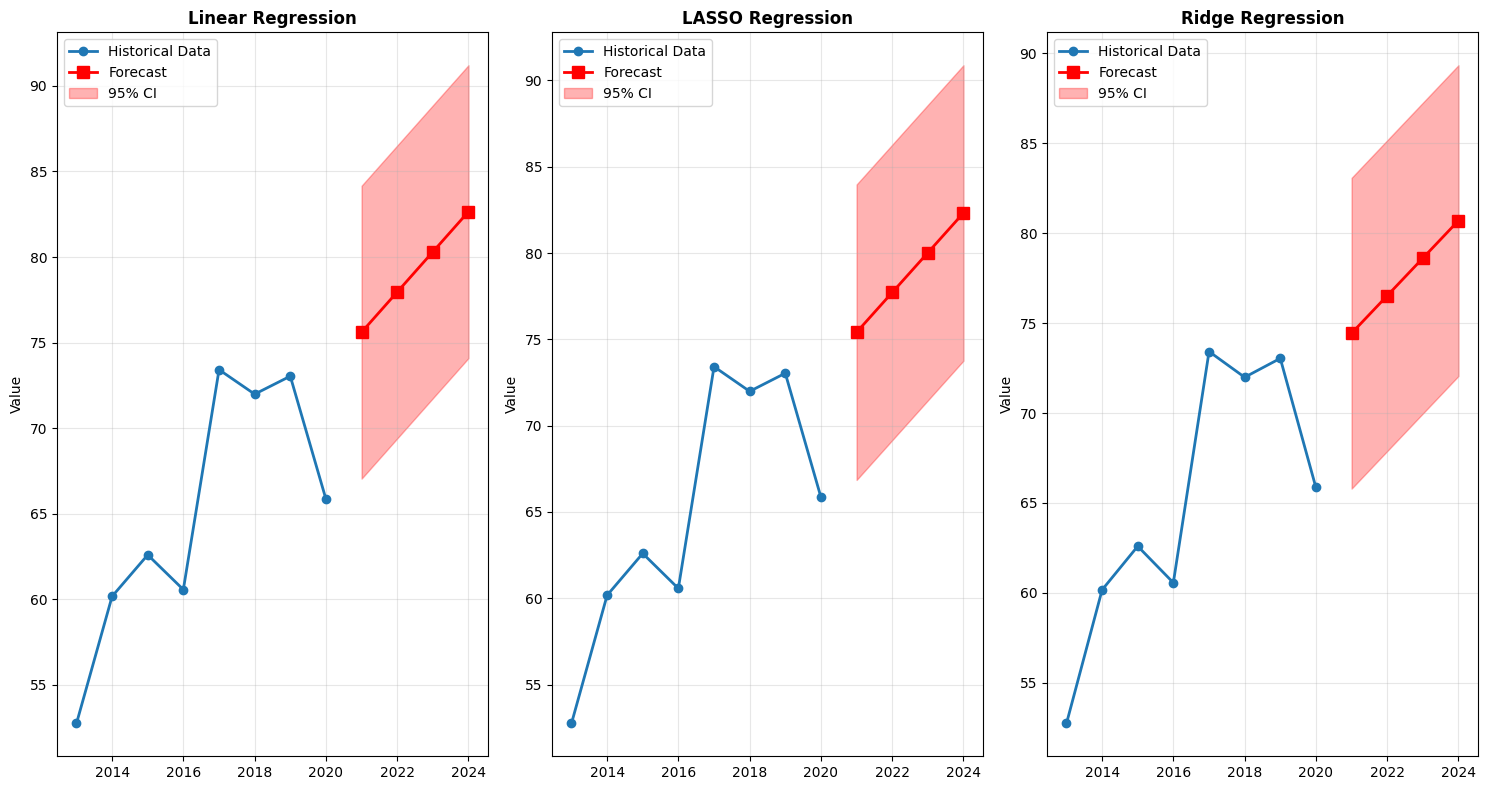

In [93]:
forecaster2.generate_forecast_report()
forecaster2.plot_forecasts()

In [94]:
# Extract test values for validation
actual_test_values = Y_test_df_aus['y'].values 

In [96]:
# Compare against actual test values
evaluation = forecaster2.evaluate_forecasts(actual_test_values)

In [97]:
evaluation

{'linear_regression': {'MAE': 7.841651785714287,
  'MSE': 71.56618321454164,
  'RMSE': np.float64(8.45967985295789),
  'MAPE': np.float64(9.236821411979697)},
 'lasso': {'MAE': 8.00531520339128,
  'MSE': 74.65021894835186,
  'RMSE': np.float64(8.640035818696116),
  'MAPE': np.float64(9.40499017503729)},
 'ridge': {'MAE': 8.819396494709,
  'MSE': 92.09899856881901,
  'RMSE': np.float64(9.596822316205454),
  'MAPE': np.float64(10.241481589749295)},
 'ensemble': {'MAE': 8.222121161271527,
  'MSE': 78.95416208471448,
  'RMSE': np.float64(8.885615458971566),
  'MAPE': np.float64(9.627764392255433)}}

In [98]:
Y_test_df_aus

,ds,y,unique_id
8,2021-01-01,68.871667,1
9,2022-01-01,81.175833,1
10,2023-01-01,90.190000,1
11,2024-01-01,94.169167,1


In [99]:
Y_train_df_aus

,ds,y,unique_id
0,2013-01-01,52.751667,1
1,2014-01-01,60.172500,1
2,2015-01-01,62.596667,1
3,2016-01-01,60.568333,1
4,2017-01-01,73.416667,1
5,2018-01-01,71.986667,1
6,2019-01-01,73.037500,1
7,2020-01-01,65.861667,1
